# 03 · Training: Baselines, λ Sweep and Carbon-Aware Agents

Merges `code/train_baselines.py`, `code/train_static_sweep.py` and `code/train_carbon_agents.py`
(and replaces the `code/run_all_training.py` orchestrator).

| Part | What | Seeds | Outputs (in `01_notebook_pipeline/results/`) |
|---|---|---|---|
| A | Rule-Based Controller (no training) | 42, 100, 2026 | `tables/rbc_seed_*_{eval_trace,summary}.csv` |
| B | Cost-Only PPO, $R = -\text{cost}$ | 42, 100, 2026 | `models/ppo_cost_only_seed_*.zip`, train logs, traces, summaries |
| C | Static-λ sweep, $R = -\text{cost} - \lambda\,\text{carbon}$ | 42 | `models/ppo_static_lambda_*_seed_42.zip`, `tables/static_lambda_sweep*.csv` |
| D | Static PPO (λ = 1.0) and Dynamic PPO (λ₀ = 1.0) | 42, 100, 2026 | `models/ppo_{static,dynamic}_seed_*.zip`, train logs, traces, summaries |
| E | Static-Matched PPO (λ = 0.41 = Dynamic's average weight) | 42, 100, 2026 | `models/ppo_static_lambda_0.41_seed_*.zip`, train logs, traces, summaries |

⚠️ **Slow:** each PPO run is 50,000 environment steps + one 8,760-step evaluation episode.
Parts B–E are 18 PPO runs in total.

In [1]:
# Load all shared config, reward functions, environment wrapper and helpers from notebook 01
%run ./01_setup_and_core.ipynb

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


Configuration loaded. Project root: D:\DEV\Projects\1_ResumeWorthy\SmartGridRL


## Run switches
Set a part to `False` to skip it (e.g. to re-run only the carbon-aware agents).

**Resuming:** with `SKIP_EXISTING = True`, any agent whose checkpoint and summary CSV already exist is reused instead
of retrained, so after an interruption just run this notebook again — it continues from the first unfinished agent
(the agent that was mid-training restarts from scratch).

In [2]:
import time

RUN_RBC = True
RUN_COST_ONLY = True
RUN_LAMBDA_SWEEP = True
RUN_CARBON_AGENTS = True
RUN_MATCHED_STATIC = True

SWEEP_SEED = 42
LAMBDAS_COARSE = [0.2, 1.0, 5.0]   # first sweep: orders of magnitude
LAMBDAS_FINE = [0.4, 0.6, 0.8]     # second sweep: between 0.2 and 1.0

# Resume support: skip any run whose outputs already exist in results/ (set False to retrain everything)
SKIP_EXISTING = True

run_start = time.time()
def elapsed():
    return f"[{(time.time() - run_start) / 60:.1f} min]"

## Part A — Rule-Based Controller (RBC) baseline
CityLearn's `BasicRBC` charges / discharges the battery on a fixed time-of-day schedule. It needs no training and is
fully deterministic, so all three seeds should give identical numbers. It is the reference point for
"CO₂ avoided".

In [3]:
if RUN_RBC:
    rbc_summaries = []
    for seed in SEEDS:
        summary_path = TABLES_DIR / f'rbc_seed_{seed}_summary.csv'
        if SKIP_EXISTING and summary_path.exists():
            print(f"RBC (seed {seed}) already done - reusing saved summary")
            rbc_summaries.append(pd.read_csv(summary_path).iloc[0].to_dict())
            continue
        print(f"Running RBC (seed {seed}) ... {elapsed()}")
        summary, trace = run_rbc_episode(seed)
        trace.to_csv(TABLES_DIR / f'rbc_seed_{seed}_eval_trace.csv', index=False)
        summary['reward'] = 0.0  # RBC has no reward; placeholder for a uniform summary format
        pd.DataFrame([summary]).to_csv(TABLES_DIR / f'rbc_seed_{seed}_summary.csv', index=False)
        rbc_summaries.append(summary)
    display(pd.DataFrame(rbc_summaries))

RBC (seed 42) already done - reusing saved summary
RBC (seed 100) already done - reusing saved summary
RBC (seed 2026) already done - reusing saved summary


,method,seed,cost,carbon,self_consumption,reward
0,RBC,42,4886.439947,5457.326528,0.438872,0.0
1,RBC,100,4886.439947,5457.326528,0.438872,0.0
2,RBC,2026,4886.439947,5457.326528,0.438872,0.0


## Part B — Cost-Only PPO baseline
The standard RL baseline from the literature: the agent only sees the electricity bill, $R_t = -\text{cost}_t$.
Any carbon reduction it achieves is a side-effect of price and carbon being correlated.

In [4]:
def train_or_reuse(reward_type, seed, lambda_val=None, method_label=None, name=None):
    """Calls train_and_evaluate_ppo unless this agent's checkpoint and summary already exist."""
    name = name or f"ppo_{reward_type}_seed_{seed}"
    summary_path = TABLES_DIR / f"{name}_summary.csv"
    if SKIP_EXISTING and (MODELS_DIR / f"{name}.zip").exists() and summary_path.exists():
        print(f"{method_label} (seed {seed}) already done - reusing saved summary")
        return pd.read_csv(summary_path).iloc[0].to_dict()
    return train_and_evaluate_ppo(reward_type, seed, lambda_val=lambda_val, method_label=method_label, name=name)

if RUN_COST_ONLY:
    cost_only_summaries = []
    for seed in SEEDS:
        cost_only_summaries.append(
            train_or_reuse('cost_only', seed, method_label='Cost-Only PPO'))
        print(elapsed())
    display(pd.DataFrame(cost_only_summaries))

Cost-Only PPO (seed 42) already done - reusing saved summary
[0.0 min]
Cost-Only PPO (seed 100) already done - reusing saved summary
[0.0 min]
Cost-Only PPO (seed 2026) already done - reusing saved summary
[0.0 min]


,method,seed,cost,carbon,self_consumption,reward
0,Cost-Only PPO,42,4797.338603,5094.478425,0.615410,-6407.269126
1,Cost-Only PPO,100,4886.432693,5581.079464,0.559946,-6399.583270
2,Cost-Only PPO,2026,4524.860432,5101.511571,0.672316,-6189.085575


## Part C — Static λ sweep (seed 42)
The static carbon-aware reward needs a hand-picked λ. We sweep it to (1) choose the λ used in Part D and
(2) show how sensitive the static formulation is to this choice — a large λ can make the carbon term dominate
and destabilise learning.

The sweep runs on one seed only, to keep the cost of tuning bounded.

In [5]:
def run_lambda_sweep(lambdas, seed=SWEEP_SEED):
    rows = []
    for l_val in lambdas:
        path = model_path('static', seed, lambda_val=l_val)
        if SKIP_EXISTING and path.exists():
            # Already trained: only re-run the (fast) evaluation episode
            print(f"\nlambda = {l_val} already trained - loading checkpoint and evaluating ... {elapsed()}")
            env = make_env(reward_type='static', lambda_val=l_val, seed=seed)
            model = PPO.load(path, env=env)
        else:
            print(f"\nTraining static carbon-aware agent with lambda = {l_val} ... {elapsed()}")
            model, env, _ = train_ppo('static', seed, lambda_val=l_val, verbose=0)
            model.save(path)
        summary, _ = run_policy_episode(model, env, seed, method=f'Static lambda={l_val}')
        print(f"lambda = {l_val}: Cost = {summary['cost']:.2f}, Carbon = {summary['carbon']:.2f}")
        rows.append({'lambda': l_val, 'cost': summary['cost'], 'carbon': summary['carbon']})
    return pd.DataFrame(rows)

if RUN_LAMBDA_SWEEP:
    sweep_coarse = run_lambda_sweep(LAMBDAS_COARSE)
    sweep_coarse.to_csv(TABLES_DIR / 'static_lambda_sweep_results.csv', index=False)

    sweep_fine = run_lambda_sweep(LAMBDAS_FINE)
    sweep_fine.to_csv(TABLES_DIR / 'static_lambda_sweep_fine_results.csv', index=False)


lambda = 0.2 already trained - loading checkpoint and evaluating ... [0.0 min]


lambda = 0.2: Cost = 4827.76, Carbon = 4978.78

lambda = 1.0 already trained - loading checkpoint and evaluating ... [2.7 min]


lambda = 1.0: Cost = 4726.20, Carbon = 5258.14

lambda = 5.0 already trained - loading checkpoint and evaluating ... [5.3 min]


lambda = 5.0: Cost = 5315.20, Carbon = 5335.35

lambda = 0.4 already trained - loading checkpoint and evaluating ... [8.0 min]


lambda = 0.4: Cost = 4791.20, Carbon = 5046.92

lambda = 0.6 already trained - loading checkpoint and evaluating ... [10.6 min]


lambda = 0.6: Cost = 4838.47, Carbon = 5111.18

lambda = 0.8 already trained - loading checkpoint and evaluating ... [12.2 min]


lambda = 0.8: Cost = 4865.21, Carbon = 5053.03


### Sweep results
Each point is one fully trained agent. Lower-left is better on both objectives.

,lambda,cost,carbon
0,0.2,4827.763006,4978.776871
1,0.4,4791.204513,5046.916942
2,0.6,4838.474813,5111.175734
3,0.8,4865.213631,5053.030109
4,1.0,4726.195128,5258.135769
5,5.0,5315.204086,5335.351702


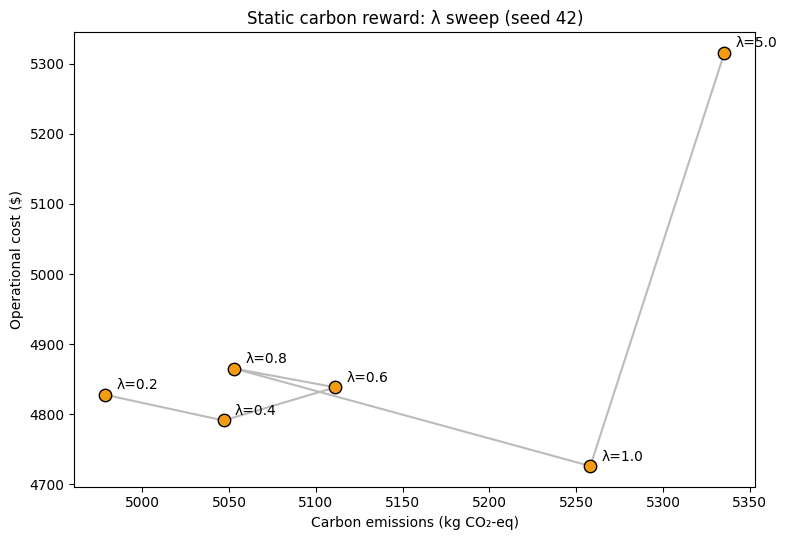

In [6]:
import matplotlib.pyplot as plt
# CityLearn switches matplotlib to the non-interactive Agg backend on import; switch back so plots show inline
%matplotlib inline

sweep_all = pd.concat([
    pd.read_csv(TABLES_DIR / 'static_lambda_sweep_results.csv'),
    pd.read_csv(TABLES_DIR / 'static_lambda_sweep_fine_results.csv'),
]).sort_values('lambda').reset_index(drop=True)
display(sweep_all)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(sweep_all['carbon'], sweep_all['cost'], '-', color='#bbbbbb', zorder=1)
ax.scatter(sweep_all['carbon'], sweep_all['cost'], s=80, color=METHOD_COLORS['Static'], edgecolor='black', zorder=2)
for _, r in sweep_all.iterrows():
    ax.annotate(f"λ={r['lambda']}", (r['carbon'], r['cost']), textcoords='offset points', xytext=(8, 4))
ax.set_xlabel('Carbon emissions (kg CO₂-eq)')
ax.set_ylabel('Operational cost ($)')
ax.set_title(f'Static carbon reward: λ sweep (seed {SWEEP_SEED})')
fig.tight_layout()
fig.savefig(PLOTS_DIR / 'static_lambda_sweep.png', dpi=200)
plt.show()

## Part D — Carbon-aware agents: Static vs Dynamic
Both use the same base weight λ = λ₀ = `LAMBDA_MAIN` (1.0), chosen from the sweep, so the **only** difference
between them is whether the carbon weight is constant or scaled by the grid's real-time carbon intensity:

- **Static:** $R_t = -\text{cost}_t - \lambda\,\text{carbon}_t$
- **Dynamic (proposed):** $R_t = -\text{cost}_t - \lambda_0 \hat I_t\,\text{carbon}_t$

In [7]:
if RUN_CARBON_AGENTS:
    carbon_summaries = []
    for seed in SEEDS:
        carbon_summaries.append(
            train_or_reuse('static', seed, lambda_val=LAMBDA_MAIN, method_label='Static-weighted PPO'))
        print(elapsed())
        carbon_summaries.append(
            train_or_reuse('dynamic', seed, lambda_val=LAMBDA_MAIN, method_label='Dynamic-weighted PPO'))
        print(elapsed())
    display(pd.DataFrame(carbon_summaries))

Static-weighted PPO (seed 42) already done - reusing saved summary
[13.2 min]
Dynamic-weighted PPO (seed 42) already done - reusing saved summary
[13.2 min]
Static-weighted PPO (seed 100) already done - reusing saved summary
[13.2 min]
Dynamic-weighted PPO (seed 100) already done - reusing saved summary
[13.2 min]
Static-weighted PPO (seed 2026) already done - reusing saved summary
[13.2 min]
Dynamic-weighted PPO (seed 2026) already done - reusing saved summary
[13.2 min]


,method,seed,cost,carbon,self_consumption,reward
0,Static-weighted PPO,42,4726.195128,5258.135769,0.596434,-14805.663092
1,Dynamic-weighted PPO,42,4897.835421,5096.885127,0.603455,-10354.703916
2,Static-weighted PPO,100,4756.498084,5583.368010,0.554743,-14878.773472
3,Dynamic-weighted PPO,100,4748.531245,5435.961354,0.558583,-10180.989941
4,Static-weighted PPO,2026,4525.711388,5211.926230,0.680846,-14459.002166
5,Dynamic-weighted PPO,2026,4489.976844,5049.998745,0.673190,-9902.145854


## Part E — Matched-average static baseline (Static-Matched)
With λ₀ = 1 the dynamic agent's effective weight $\lambda_0 \hat I_t$ averages only about **0.41** over the year, so
Static λ = 1 penalises carbon about 2.5× harder **on average**. To test whether the dynamic agent's advantage comes from
*following carbon intensity* rather than just from *a smaller average weight*, we train a static agent whose fixed
weight equals the dynamic agent's average: λ = `LAMBDA_MATCHED`.

| Agent | Weight at the cleanest hour | at the dirtiest hour | Yearly average |
|---|---|---|---|
| Static-Matched | λ_matched | λ_matched | λ_matched ≈ 0.41 |
| Dynamic | 0 | λ₀ = 1 | ≈ 0.41 |

First we check the yearly mean of $\hat I_t$ directly from the dataset.

In [8]:
check_env = make_env(reward_type='dynamic', lambda_val=LAMBDA_MAIN)
ci = np.array(check_env.env.buildings[0].carbon_intensity._carbon_intensity, dtype=np.float64)
i_hat = np.clip((ci - check_env.carbon_min) / (check_env.carbon_max - check_env.carbon_min), 0, 1)
print(f"Mean normalised carbon intensity over the year: {i_hat.mean():.4f}")
print(f"-> dynamic agent's average carbon weight = {LAMBDA_MAIN * i_hat.mean():.4f}; LAMBDA_MATCHED = {LAMBDA_MATCHED}")

Mean normalised carbon intensity over the year: 0.4075
-> dynamic agent's average carbon weight = 0.4075; LAMBDA_MATCHED = 0.41


In [9]:
if RUN_MATCHED_STATIC:
    matched_summaries = []
    for seed in SEEDS:
        matched_summaries.append(
            train_or_reuse('static', seed, lambda_val=LAMBDA_MATCHED,
                           method_label='Static-Matched PPO', name=run_name('Static-Matched', seed)))
        print(elapsed())
    display(pd.DataFrame(matched_summaries))


=== Training Static-Matched PPO (seed 42, lambda=0.41) ===


  Episode 1 (Step 8759): Reward=-10547.88, Cost=7005.30, Carbon=8640.44


  Episode 2 (Step 17518): Reward=-10513.47, Cost=6922.64, Carbon=8758.12


  Episode 3 (Step 26277): Reward=-10350.16, Cost=6786.30, Carbon=8692.36


  Episode 4 (Step 35036): Reward=-10155.28, Cost=6606.28, Carbon=8656.11


...

  Episode 3 (Step 26277): Reward=-10023.71, Cost=6562.65, Carbon=8441.62


  Episode 4 (Step 35036): Reward=-9834.51, Cost=6400.91, Carbon=8374.63


  Episode 5 (Step 43795): Reward=-9602.11, Cost=6222.47, Carbon=8243.01


Eval: Cost = 4543.93, Carbon = 4983.22
[43.6 min]


,method,seed,cost,carbon,self_consumption,reward
0,Static-Matched PPO,42,4636.381816,5042.065971,0.628746,-9970.206116
1,Static-Matched PPO,100,4939.125981,5431.235484,0.565286,-9908.798656
2,Static-Matched PPO,2026,4543.932900,4983.222470,0.685823,-9602.105536


## Training summary
Final evaluation episode of every agent trained above (read back from the saved summary CSVs).
Notebook 04 re-evaluates all checkpoints from disk and builds the final comparison table.

In [10]:
summary_files = sorted(TABLES_DIR.glob('*_seed_*_summary.csv'))
all_summaries = pd.concat([pd.read_csv(f) for f in summary_files], ignore_index=True)
print(f"Total training time: {elapsed()}")
all_summaries.sort_values(['method', 'seed']).reset_index(drop=True)

Total training time: [43.6 min]


,method,seed,cost,carbon,self_consumption,reward
0,Cost-Only PPO,42,4797.338603,5094.478425,0.615410,-6407.269126
1,Cost-Only PPO,100,4886.432693,5581.079464,0.559946,-6399.583270
2,Cost-Only PPO,2026,4524.860432,5101.511571,0.672316,-6189.085575
3,Dynamic-weighted PPO,42,4897.835421,5096.885127,0.603455,-10354.703916
4,Dynamic-weighted PPO,100,4748.531245,5435.961354,0.558583,-10180.989941
5,Dynamic-weighted PPO,2026,4489.976844,5049.998745,0.673190,-9902.145854
6,RBC,42,4886.439947,5457.326528,0.438872,0.000000
7,RBC,100,4886.439947,5457.326528,0.438872,0.000000
8,RBC,2026,4886.439947,5457.326528,0.438872,0.000000
9,Static-Matched PPO,42,4636.381816,5042.065971,0.628746,-9970.206116
